# Numerical Methods: Used Car Price Prediction

## Project Description
A used car sales company is developing a new feature for its app that automatically determines the market value of a car.

**Goal:** Build a model that determines the price of a car from its technical characteristics, equipment and other data.

Optimization criteria:
- prediction quality;
- prediction speed;
- training time.

**Tasks:**
1. Load and prepare the data.
2. Train different models, trying different hyperparameters for each.
3. Analyze the speed and the quality of the models.

## Data Description
The data is stored in the file `autos.csv`.

- **Features**
    - `DateCrawled` - date the ad was downloaded from the database
    - `VehicleType` - car body type
    - `RegistrationYear` - year of car registration
    - `Gearbox` - gearbox type
    - `Power` - power (hp)
    - `Model` - car model
    - `Kilometer` - mileage (km)
    - `RegistrationMonth` - month of car registration
    - `FuelType` - fuel type
    - `Brand` - car brand
    - `NotRepaired` - whether the car has been repaired or not
    - `DateCreated` - date the ad was created
    - `NumberOfPictures` - number of car photos
    - `PostalCode` - postal code of the ad owner (user)
    - `LastSeen` - date of the user's last activity

- **Target feature**
    - `Price` - price (euro)

**Plan:**
- 1. Data Preparation
    - 1.1 Data exploration
    - 1.2 Data preprocessing
    - 1.3 Encoding of categorical features
    - 1.4 Preparing the samples
- 2. Model Training
    - 2.1 Linear regression
    - 2.2 Lasso/Ridge
    - 2.3 LightGBM
- 3. Model Analysis

# 1. Data Preparation

## 1.1 Data Exploration

In [1]:
import pandas as pd
import numpy as np
import re
from scipy import stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from numpy.random import RandomState
from scipy import stats

from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, make_scorer
import lightgbm
import catboost
%matplotlib inline

Load the data from the file, print the first 10 rows for a first look at the data and study the table structure with `info()`: data types, number of rows and columns, missing values.

In [2]:
data = pd.read_csv('autos.csv')
# in some versions of the dataset the column `NotRepaired` is named `Repaired`
data = data.rename(columns={'Repaired': 'NotRepaired'})
display(data.head(10))
print(data.info())
print('Number of duplicates:', sum(data.duplicated()))

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21
5,2016-04-04 17:36:23,650,sedan,1995,manual,102,3er,150000,10,petrol,bmw,yes,2016-04-04 00:00:00,0,33775,2016-04-06 19:17:07
6,2016-04-01 20:48:51,2200,convertible,2004,manual,109,2_reihe,150000,8,petrol,peugeot,no,2016-04-01 00:00:00,0,67112,2016-04-05 18:18:39
7,2016-03-21 18:54:38,0,sedan,1980,manual,50,other,40000,7,petrol,volkswagen,no,2016-03-21 00:00:00,0,19348,2016-03-25 16:47:58
8,2016-04-04 23:42:13,14500,bus,2014,manual,125,c_max,30000,8,petrol,ford,NaN,2016-04-04 00:00:00,0,94505,2016-04-04 23:42:13
9,2016-03-17 10:53:50,999,small,1998,manual,101,golf,150000,0,NaN,volkswagen,NaN,2016-03-17 00:00:00,0,27472,2016-03-31 17:17:06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  NotRepaired        283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

Number of duplicates: 4


In [3]:
data.describe()

,Price,RegistrationYear,Power,Kilometer,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


- The features `NumberOfPictures` and `PostalCode` carry no useful information, so they are removed.
- `DateCrawled` also repeats the date in `DateCreated`.
- `Brand` is most likely redundant when the specific car model is given in `Model`.
- `RegistrationMonth` is distributed uniformly and by its meaning is unlikely to affect the price of a car.
- Remove the duplicates and the uninformative features.

In [4]:
data = data.drop(['NumberOfPictures', 'PostalCode', 'DateCrawled', 'RegistrationMonth'], axis=1)

In [5]:
numerical_features = ['DateCreated', 'Price', 'RegistrationYear', 'Power', 'Kilometer', 'LastSeen']
categorical_features = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'NotRepaired', 'Brand']

- Plot the distributions of the numerical features and their dependence on the target feature `Price`.

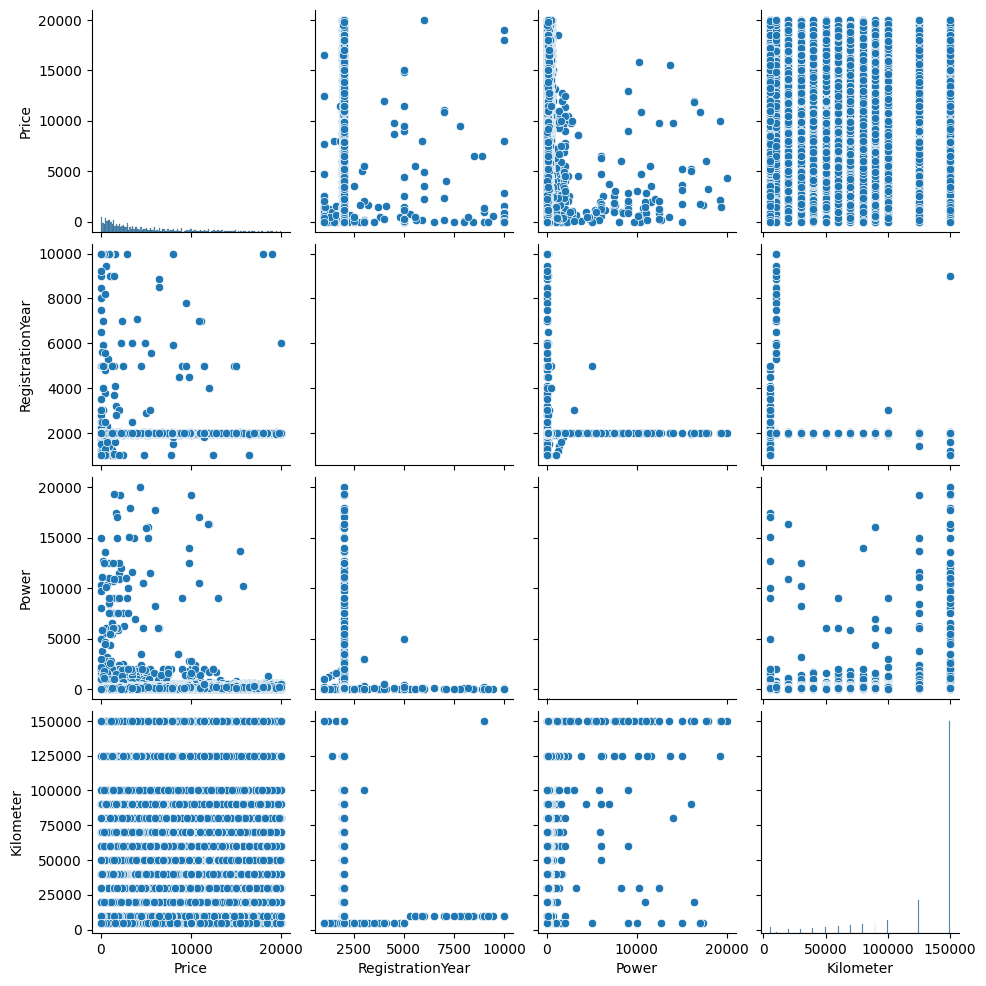

In [6]:
sns.pairplot(data)

## 1.2 Data Preprocessing

- Select the features needed to build the model.
- Handle the missing values and outliers.

In [7]:
# first remove the duplicates
data = data.drop_duplicates()

- Feature `Price`

In [8]:
f"Number of ads with zero price: {len(data.loc[data['Price'] == 0])}"

'Number of ads with zero price: 10771'

Zero prices are clearly erroneous (or the sellers did not specify a price in the ad). There is no way to restore the target feature for these objects, so they are removed so as not to spoil the model.

In [9]:
data = data.loc[data['Price'] != 0]

<Axes: xlabel='Price', ylabel='Count'>

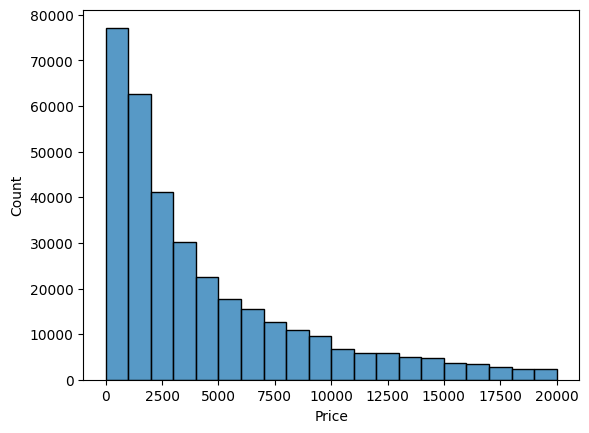

In [10]:
sns.histplot(data['Price'], bins=20)

- Feature `Model`

In [11]:
f"Number of ads with missing model: {len(data.loc[data['Model'].isna()])}"

'Number of ads with missing model: 17520'

`Model` is one of the main features for predicting the price. 5% of its values are missing. These values cannot be restored correctly, so the missing values are removed.

In [12]:
data = data.loc[~data['Model'].isna()]

- Feature `Power`

In [13]:
f"Number of cars with power > 1000 hp or <= 0: {len(data.loc[(data['Power'] > 1000) | (data['Power'] <= 0)])}"

'Number of cars with power > 1000 hp or <= 0: 31583'

A power above 1000 hp is implausible. Replace all implausible values (and zeros) with the median power of cars of the same model.

In [14]:
data.loc[(data['Power'] > 1000) | (data['Power'] <= 0), 'Power'] = None
data['Power'] = data['Power'].fillna(data.groupby('Model')['Power'].transform('median'))
data = data.loc[~data['Power'].isna()]
data['Power'] = data['Power'].astype('int64')

<Axes: xlabel='Power', ylabel='Count'>

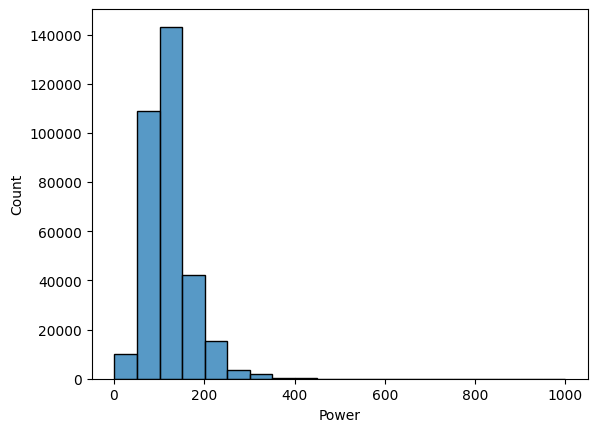

In [15]:
sns.histplot(data['Power'], bins=20)

<Axes: xlabel='Power', ylabel='Price'>

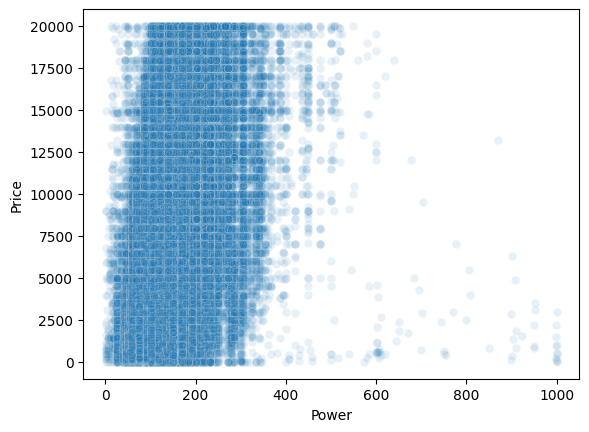

In [16]:
sns.scatterplot(x='Power', y='Price', data=data, alpha = 0.1)

- Features `DateCreated` and `LastSeen`

In [17]:
f"Earliest ad creation date: {min(data['DateCreated'])}"

'Earliest ad creation date: 2014-03-10 00:00:00'

Convert `DateCreated` and `LastSeen` to the number of days since `2014-03-01`.

In [18]:
base_date = pd.Timestamp('2014-03-01 00:00:00')
data['DateCreated'] = data['DateCreated'].map(lambda date : (pd.Timestamp(date) - base_date).days)

In [19]:
data['LastSeen'] = data['LastSeen'].map(lambda date : (pd.Timestamp(date) - base_date).days)

- Feature `RegistrationYear`

In [20]:
f"Number of ads with an incorrect registration year: {len(data.loc[data['RegistrationYear'] > 2020])}"

'Number of ads with an incorrect registration year: 58'

In [21]:
data.loc[data['RegistrationYear'] > 2020].head(10)

,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,FuelType,Brand,NotRepaired,DateCreated,LastSeen
12946,49,NaN,5000,NaN,101,golf,5000,NaN,volkswagen,NaN,759,767
17271,700,NaN,9999,NaN,116,other,10000,NaN,opel,NaN,753,766
18259,300,NaN,2200,NaN,58,twingo,5000,NaN,renault,NaN,746,768
26382,150,NaN,3000,NaN,95,a_klasse,5000,NaN,mercedes_benz,NaN,737,738
26560,800,NaN,2066,NaN,125,zafira,5000,gasoline,opel,NaN,754,759
28390,799,NaN,9999,NaN,150,3er,10000,petrol,bmw,NaN,766,768
28965,18000,NaN,9999,NaN,95,a_klasse,10000,petrol,mercedes_benz,NaN,765,768
29426,7999,NaN,9999,NaN,44,kaefer,10000,NaN,volkswagen,NaN,753,767
40954,59,NaN,8000,NaN,116,other,10000,NaN,chevrolet,NaN,737,768
45662,999,NaN,9000,NaN,69,fiesta,10000,NaN,ford,yes,753,766


A price with an incorrect registration year is also hard to predict, and such ads may introduce errors into the model. There are few such objects and many of their other features are missing too, so these ads are removed.

In [22]:
data = data.loc[data['RegistrationYear'] <= 2020]

- Features `VehicleType`, `Gearbox`, `FuelType`

These parameters are most likely the same for cars of the same model. Fill the missing values of these features with the most frequent value among the cars of the same model.

In [23]:
data['VehicleType'] = data['VehicleType'].fillna(data
                                                  .groupby('Model')['VehicleType']
                                                  .transform(lambda x: x.value_counts().idxmax())
                                                 )

In [24]:
data['Gearbox'] = data['Gearbox'].fillna(data
                                         .groupby('Model')['Gearbox']
                                         .transform(lambda x: x.mode().get(0))
                                        )

In [25]:
data['FuelType'] = data['FuelType'].fillna(data
                                           .groupby('Model')['FuelType']
                                           .transform(lambda x: x.mode().get(0))
                                          )

- Feature `NotRepaired`

In [26]:
data['NotRepaired'] = data['NotRepaired'].fillna('unknown')

- Look at the data after handling the missing values and outliers.

In [27]:
data.head(10)

,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,FuelType,Brand,NotRepaired,DateCreated,LastSeen
0,480,sedan,1993,manual,101,golf,150000,petrol,volkswagen,unknown,754,768
2,9800,suv,2004,auto,163,grand,125000,gasoline,jeep,unknown,744,766
3,1500,small,2001,manual,75,golf,150000,petrol,volkswagen,no,747,747
4,3600,small,2008,manual,69,fabia,90000,gasoline,skoda,no,761,767
5,650,sedan,1995,manual,102,3er,150000,petrol,bmw,yes,765,767
6,2200,convertible,2004,manual,109,2_reihe,150000,petrol,peugeot,no,762,766
8,14500,bus,2014,manual,125,c_max,30000,petrol,ford,unknown,765,765
9,999,small,1998,manual,101,golf,150000,petrol,volkswagen,unknown,747,761
10,2000,sedan,2004,manual,105,3_reihe,150000,petrol,mazda,no,756,767
11,2799,wagon,2005,manual,140,passat,150000,gasoline,volkswagen,yes,768,768


In [28]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 325909 entries, 0 to 354368
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Price             325909 non-null  int64 
 1   VehicleType       325909 non-null  object
 2   RegistrationYear  325909 non-null  int64 
 3   Gearbox           325909 non-null  object
 4   Power             325909 non-null  int64 
 5   Model             325909 non-null  object
 6   Kilometer         325909 non-null  int64 
 7   FuelType          325909 non-null  object
 8   Brand             325909 non-null  object
 9   NotRepaired       325909 non-null  object
 10  DateCreated       325909 non-null  int64 
 11  LastSeen          325909 non-null  int64 
dtypes: int64(6), object(6)
memory usage: 32.3+ MB


## 1.3 Encoding of Categorical Features

- `Model` has many categories. Combine it with `Brand` and encode it with the value **Model.size() / Brand.size()**.

In [29]:
data['brand_model'] = data['Brand'].astype(str) + ' ' + data['Model'].astype(str)
data['model_code'] = data['brand_model'].map(data.groupby('brand_model').size()) / \
                     data['Brand'].map(data.groupby('Brand').size())
data_coded = data.drop(['brand_model', 'Brand', 'Model'], axis=1)

- Encode `VehicleType`, `Gearbox`, `FuelType` and `NotRepaired` with one-hot encoding.

In [30]:
def get_dummies_func(data, column, prefix):
    df = pd.get_dummies(data[column], prefix=prefix, drop_first=True)
    data = data.drop(column, axis=1)
    return data.join(df)

In [31]:
data_coded = get_dummies_func(data_coded, 'VehicleType', 'VType')

In [32]:
data_coded = get_dummies_func(data_coded, 'Gearbox', 'Gear')

In [33]:
data_coded = get_dummies_func(data_coded, 'FuelType', 'Fuel')

In [34]:
data_coded = get_dummies_func(data_coded, 'NotRepaired', 'Repair')

In [35]:
data_coded.head(10)

,Price,RegistrationYear,Power,Kilometer,DateCreated,LastSeen,model_code,VType_convertible,VType_coupe,VType_other,...,VType_wagon,Gear_manual,Fuel_electric,Fuel_gasoline,Fuel_hybrid,Fuel_lpg,Fuel_other,Fuel_petrol,Repair_unknown,Repair_yes
0,480,1993,101,150000,754,768,0.396043,0,0,0,...,0,1,0,0,0,0,0,1,1,0
2,9800,2004,163,125000,744,766,0.373817,0,0,0,...,0,0,0,1,0,0,0,0,1,0
3,1500,2001,75,150000,747,747,0.396043,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,3600,2008,69,90000,761,767,0.388051,0,0,0,...,0,1,0,1,0,0,0,0,0,0
5,650,1995,102,150000,765,767,0.562788,0,0,0,...,0,1,0,0,0,0,0,1,0,1
6,2200,2004,109,150000,762,766,0.478545,1,0,0,...,0,1,0,0,0,0,0,1,0,0
8,14500,2014,125,30000,765,765,0.028982,0,0,0,...,0,1,0,0,0,0,0,1,1,0
9,999,1998,101,150000,747,761,0.396043,0,0,0,...,0,1,0,0,0,0,0,1,1,0
10,2000,2004,105,150000,756,767,0.249660,0,0,0,...,0,1,0,0,0,0,0,1,0,0
11,2799,2005,140,150000,768,768,0.137974,0,0,0,...,1,1,0,1,0,0,0,0,0,1


## 1.4 Preparing the Samples

- Select the features and the target feature. Split the data into training and test sets in the ratio 4:1.

In [36]:
X = data_coded.drop('Price', axis=1)
y = data_coded['Price']

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
f"Training set size: {X_train.shape}"

'Training set size: (260727, 22)'

In [39]:
f"Test set size: {X_test.shape}"

'Test set size: (65182, 22)'

- Scale the features to the standard normal distribution with `StandardScaler` from `sklearn`.

In [40]:
ss = StandardScaler()
ss.fit(X_train)
columns = X_train.columns
X_train = pd.DataFrame(ss.transform(X_train), columns = columns)
X_test = pd.DataFrame(ss.transform(X_test), columns = columns)

In [41]:
X_train.head(10)

,RegistrationYear,Power,Kilometer,DateCreated,LastSeen,model_code,VType_convertible,VType_coupe,VType_other,VType_sedan,...,VType_wagon,Gear_manual,Fuel_electric,Fuel_gasoline,Fuel_hybrid,Fuel_lpg,Fuel_other,Fuel_petrol,Repair_unknown,Repair_yes
0,-0.019555,-0.340781,0.579140,0.446150,0.702209,-0.913564,-0.250460,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,1.515999,-0.025768,-0.12302,-0.018991,-1.454438,-0.466591,-0.329923
1,-0.685446,-1.112035,-1.581784,1.403893,0.919999,-0.366058,-0.250460,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,-0.466591,-0.329923
2,-0.400064,-0.321970,0.579140,0.233318,-0.495635,-1.001901,-0.250460,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,1.515999,-0.025768,-0.12302,-0.018991,-1.454438,2.143203,-0.329923
3,0.075572,0.580962,-3.337534,0.339734,0.266629,-0.929287,-0.250460,-0.221351,-0.09011,-0.662243,...,2.008802,-2.036097,-0.014657,1.515999,-0.025768,-0.12302,-0.018991,-1.454438,-0.466591,3.031012
4,-0.019555,-0.058615,0.579140,-0.724425,0.375524,0.017244,-0.250460,-0.221351,-0.09011,-0.662243,...,2.008802,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,-0.466591,-0.329923
5,-0.304937,-0.848680,-0.096149,1.084646,0.811104,-0.263466,-0.250460,-0.221351,-0.09011,-0.662243,...,2.008802,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,2.143203,-0.329923
6,-0.114683,-0.961547,0.579140,0.658982,0.919999,0.883360,-0.250460,-0.221351,-0.09011,-0.662243,...,2.008802,0.491136,-0.014657,1.515999,-0.025768,-0.12302,-0.018991,-1.454438,-0.466591,-0.329923
7,0.170699,-1.224902,0.579140,-0.830840,-1.475689,-0.366058,-0.250460,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,2.143203,-0.329923
8,-0.495191,-0.340781,0.579140,0.552566,0.811104,0.883360,3.992659,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,-0.466591,-0.329923
9,-0.495191,-1.300146,0.579140,-0.085929,-1.040110,0.511772,-0.250460,-0.221351,-0.09011,-0.662243,...,-0.497809,0.491136,-0.014657,-0.659631,-0.025768,-0.12302,-0.018991,0.687551,-0.466591,-0.329923


### Conclusions

- The data is loaded and analyzed successfully. The data types match the description, the duplicates are removed.
- The features needed to build the models are selected.
- The missing values, outliers and implausible values are filled with the help of the available information where possible. The other objects are removed (about 8% of the data).
- Categorical features with few categories are converted with one-hot encoding. `Model` is encoded with the formula **Model.size() / Brand.size()**.
- The data is split into training and test sets in the ratio 4:1, the features are scaled to the standard normal distribution.

# 2. Model Training

- First, create a constant baseline model that always predicts the mean value of `Price` (in practice the mean gave a lower RMSE than the median). Calculate the RMSE of the baseline model.

In [42]:
preds_base = pd.Series(data=y.mean(), index=y.index, dtype='int64')
rmse_base = mean_squared_error(y, preds_base) ** 0.5
f"RMSE of the constant model: {round(rmse_base, 2)}"

'RMSE of the constant model: 4530.45'

## 2.1 Linear Regression

- First, train a linear model. Measure the training time, the prediction time and the RMSE of the model. The model is evaluated with 5-fold cross-validation.

In [43]:
%%time
lm = LinearRegression()
mse = cross_val_score(lm, X_train, y_train, cv=5, scoring='neg_mean_squared_error')

CPU times: user 863 ms, sys: 1.16 s, total: 2.03 s
Wall time: 1.85 s


In [44]:
f"RMSE of the linear model on the validation set: {round((-mse.mean()) ** 0.5, 2)}"

'RMSE of the linear model on the validation set: 3004.99'

In [45]:
%%time
lm = LinearRegression()
lm.fit(X_train, y_train)

CPU times: user 158 ms, sys: 51.9 ms, total: 210 ms
Wall time: 210 ms


LinearRegression()

In [46]:
%%time
preds_lm = lm.predict(X_test)

CPU times: user 4.45 ms, sys: 250 µs, total: 4.7 ms
Wall time: 4.85 ms


In [47]:
mse_lm = mean_squared_error(y_test, preds_lm)
f"RMSE of the linear model on the test set: {round((mse_lm) ** 0.5, 2)}"

'RMSE of the linear model on the test set: 3023.02'

## 2.2 Lasso/Ridge

- Try to train linear models with L1 and L2 regularization.

**1) Lasso** (L1 regularization)

In [48]:
%%time
alphas = np.arange(1, 40, 4)
for alpha in alphas :
    lasso = Lasso(alpha = alpha)
    mse = cross_val_score(lasso, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    print("RMSE of the Lasso model with alpha={:.2f} on the validation set: {:.2f}".format(alpha, (-mse.mean()) ** 0.5))

RMSE of the Lasso model with alpha=1.00 on the validation set: 3004.99


RMSE of the Lasso model with alpha=5.00 on the validation set: 3005.08


RMSE of the Lasso model with alpha=9.00 on the validation set: 3005.30


RMSE of the Lasso model with alpha=13.00 on the validation set: 3005.63


RMSE of the Lasso model with alpha=17.00 on the validation set: 3006.02


RMSE of the Lasso model with alpha=21.00 on the validation set: 3006.52


RMSE of the Lasso model with alpha=25.00 on the validation set: 3007.09


RMSE of the Lasso model with alpha=29.00 on the validation set: 3007.74


RMSE of the Lasso model with alpha=33.00 on the validation set: 3008.46


RMSE of the Lasso model with alpha=37.00 on the validation set: 3009.21
CPU times: user 39.2 s, sys: 6.42 s, total: 45.6 s
Wall time: 44.3 s


In [49]:
%%time
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

CPU times: user 8.12 s, sys: 450 ms, total: 8.57 s
Wall time: 8.53 s


Lasso(alpha=0.1)

In [50]:
%%time
preds_ls = lasso.predict(X_test)

CPU times: user 751 µs, sys: 4.16 ms, total: 4.91 ms
Wall time: 5.54 ms


In [51]:
mse_ls = mean_squared_error(y_test, preds_ls)
f"RMSE of the Lasso model on the test set: {round((mse_ls) ** 0.5, 2)}"

'RMSE of the Lasso model on the test set: 3023.02'

- Lasso gave no gain in the metric, and its training is much slower than that of the linear model without regularization (several seconds against a fraction of a second). The prediction speed is the same.

**2) Ridge** (L2 regularization)

In [52]:
%%time
alphas = np.arange(1, 40, 4)
for alpha in alphas :
    ridge = Ridge(alpha = alpha)
    mse = cross_val_score(ridge, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    print("RMSE of the Ridge model with alpha={:.2f} on the validation set: {:.2f}".format(alpha, (-mse.mean()) ** 0.5))

RMSE of the Ridge model with alpha=1.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=5.00 on the validation set: 3004.99
RMSE of the Ridge model with alpha=9.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=13.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=17.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=21.00 on the validation set: 3004.99
RMSE of the Ridge model with alpha=25.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=29.00 on the validation set: 3004.99
RMSE of the Ridge model with alpha=33.00 on the validation set: 3004.99


RMSE of the Ridge model with alpha=37.00 on the validation set: 3004.99
CPU times: user 1.76 s, sys: 537 ms, total: 2.3 s
Wall time: 2.28 s


In [53]:
%%time
ridge = Ridge(alpha=0.5)
ridge.fit(X_train, y_train)

CPU times: user 29.6 ms, sys: 7.79 ms, total: 37.4 ms
Wall time: 38 ms


Ridge(alpha=0.5)

In [54]:
%%time
preds_rg = ridge.predict(X_test)

CPU times: user 3.98 ms, sys: 0 ns, total: 3.98 ms
Wall time: 4.68 ms


In [55]:
mse_rg = mean_squared_error(y_test, preds_rg)
f"RMSE of the Ridge model on the test set: {round((mse_rg) ** 0.5, 2)}"

'RMSE of the Ridge model on the test set: 3023.02'

- Ridge gave no gain in the metric. Its training is faster than that of the linear model without regularization (in this run several times faster, tens of milliseconds against about 230 ms).

## 2.3 LightGBM

- Try to train a gradient boosting model: LightGBM.
- The parameters are selected with `GridSearchCV` from `sklearn`.

In [56]:
numerical_features = ['DateCreated', 'Price', 'RegistrationYear', 'Power', 'Kilometer', 'LastSeen']
categorical_features = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'NotRepaired', 'Brand']

In [57]:
data = data.drop(['brand_model', 'model_code'], axis=1)

In [58]:
X = data_coded.drop('Price', axis=1)
y = data_coded['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
f"Training set size: {X_train.shape}"

'Training set size: (260727, 22)'

In [60]:
f"Test set size: {X_test.shape}"

'Test set size: (65182, 22)'

In [61]:
categorical_features = [col for col in list(data_coded.columns) if col not in numerical_features]

In [62]:
%%time
train_data = lightgbm.Dataset(X_train, label=y_train, 
                              free_raw_data=False,
                              categorical_feature=categorical_features)
test_data = lightgbm.Dataset(X_test, label=y_test)

param_grid = {'learning_rate': [0.1, 0.3, 0.5, 0.7],
              'max_depth': [15, 20, 30, 35],
             }

lgbm = lightgbm.LGBMRegressor(n_jobs = 8)

# initialize GridSearchCV
grid_search = GridSearchCV(estimator = lgbm, 
                           param_grid = param_grid, 
                           cv = 3,
                           n_jobs = -1, 
                           verbose = 0, 
                           scoring = 'neg_mean_squared_error',
                          )
grid_search.fit(X_train, y_train)

CPU times: user 1.64 s, sys: 664 ms, total: 2.3 s
Wall time: 1min 31s


GridSearchCV(cv=3, estimator=LGBMRegressor(n_jobs=8), n_jobs=-1,
             param_grid={'learning_rate': [0.1, 0.3, 0.5, 0.7],
                         'max_depth': [15, 20, 30, 35]},
             scoring='neg_mean_squared_error')

In [63]:
print(grid_search.best_params_)

{'learning_rate': 0.5, 'max_depth': 15}


In [64]:
print('RMSE of the LightGBM model on the validation set: {:.2f}'.format((-grid_search.best_score_) ** 0.5))

RMSE of the LightGBM model on the validation set: 1665.08


In [65]:
%%time
preds_lgbm = grid_search.best_estimator_.predict(X_test)

CPU times: user 221 ms, sys: 7.54 ms, total: 228 ms
Wall time: 227 ms


In [66]:
mse_lgbm = mean_squared_error(y_test, preds_lgbm)
f"RMSE of the LightGBM model on the test set: {round((mse_lgbm) ** 0.5, 2)}"

'RMSE of the LightGBM model on the test set: 1644.37'

### Conclusions

- Linear regression models without and with regularization and the gradient boosting model LightGBM are trained.
- The training and prediction time and the prediction quality (RMSE) of the models are measured.

# 3. Model Analysis

- All trained models improved the RMSE of the baseline model.
- For this task the linear model without regularization showed prediction quality no worse than Lasso and Ridge. The **RMSE** of LightGBM is almost two times lower:
    - Baseline (constant model): 4530.45
    - LinearModel, Lasso, Ridge: 3023.02 on the test set (3004.99 in cross-validation)
    - **LightGBM: 1644.37** on the test set (1665.08 in cross-validation)
- **By training time** the linear model without regularization and Ridge are the fastest (a fraction of a second). Lasso is much slower than the linear model (several seconds). The whole GridSearch for LightGBM (16 parameter sets, 3-fold cross-validation) takes about a minute and a half. The times depend on the machine, so only their ratios are meaningful.
- **By prediction time** the linear models behave the same (a few milliseconds). LightGBM is a heavier model: its prediction time is more than an order of magnitude higher (about 0.2 s for the test set).
- The best quality is given by **LightGBM**. If the prediction speed is the most important criterion, a linear model is the fast alternative with a much higher RMSE.